# CARD Demo Notebook

Explore a random sample: neighbor poses (±1), stereo pairing, GT depth, ground plane, and convert depth to height above ground.

In [2]:
import os, random, numpy as np
import torch
import cv2
from pathlib import Path
from card_dataset.dataloader import UnifiedCardDataset


def chw_to_hwc_uint8(img_t, mean, std):
    img = img_t.detach().cpu().float().numpy().transpose(1, 2, 0)
    img = (img * std + mean)
    img = np.clip(img * 255.0, 0, 255).astype(np.uint8)
    return img


def compute_height_from_ground_plane(depth_pred, depth_gt, K, T_cam_world, ground_plane_info):
    """Compute height above ground plane from depth using ground plane information"""
    try:
        plane_normal_world = ground_plane_info['plane_normal_world']
        plane_point_world = ground_plane_info['plane_point_world']

        if hasattr(plane_normal_world, 'numpy'):
            plane_normal_world = plane_normal_world.numpy()
        elif hasattr(plane_normal_world, 'cpu'):
            plane_normal_world = plane_normal_world.cpu().numpy()

        if hasattr(plane_point_world, 'numpy'):
            plane_point_world = plane_point_world.numpy()
        elif hasattr(plane_point_world, 'cpu'):
            plane_point_world = plane_point_world.cpu().numpy()

        def depth_to_height(depth_map):
            h, w = depth_map.shape
            valid_mask = (depth_map > 0) & np.isfinite(depth_map)
            height_map = np.zeros_like(depth_map)
            if not np.any(valid_mask):
                return height_map
            u, v = np.meshgrid(np.arange(w), np.arange(h))
            valid_u = u[valid_mask]
            valid_v = v[valid_mask]
            valid_depth = depth_map[valid_mask]
            x_cam = (valid_u - K[0, 2]) * valid_depth / K[0, 0]
            y_cam = (valid_v - K[1, 2]) * valid_depth / K[1, 1]
            z_cam = valid_depth
            points_cam_hom = np.stack([x_cam, y_cam, z_cam, np.ones_like(valid_depth)], axis=-1)
            points_world = (T_cam_world @ points_cam_hom.T).T
            points_world_xyz = points_world[:, :3]
            plane_normal_unit = plane_normal_world / (np.linalg.norm(plane_normal_world) + 1e-8)
            vectors_to_points = points_world_xyz - plane_point_world.reshape(1, 3)
            signed_distances = np.sum(vectors_to_points * plane_normal_unit.reshape(1, 3), axis=-1)
            valid_heights = signed_distances
            height_map[valid_mask] = valid_heights
            return height_map

        height_pred = depth_to_height(depth_pred) if depth_pred is not None else None
        height_gt = depth_to_height(depth_gt) if depth_gt is not None else None
        return height_pred, height_gt
    except Exception as e:
        print('Error computing height:', e)
        return None, None

## Configure Paths

The args to the data loader, the data root, and the split file to be read

In [ ]:
HEIGHT, WIDTH = 1000, 1216
LOAD_NEIGHBORS = True
LOAD_GROUND_PLANE = True
USE_STEREO = True

DATA_ROOT = /path/to/dataset
SPLIT_FILE = val.txt


In [4]:
# Refresh config from environment for this kernel session
import os
DATA_ROOT = os.environ.get('CARD_DATA_ROOT', DATA_ROOT)
DATA_ROOT="/media/T7/cariad dataset/"

SPLIT_FILE = os.environ.get('CARD_SPLIT_FILE', SPLIT_FILE)
SPLIT_FILE="/media/T7/cariad dataset/val_all_data_clean_NN.txt"
print('DATA_ROOT =', DATA_ROOT)
print('SPLIT_FILE =', SPLIT_FILE)

DATA_ROOT = /media/T7/cariad dataset/
SPLIT_FILE = /media/T7/cariad dataset/val_all_data_clean_NN.txt


In [5]:
# Resolve split path
split_path = Path(SPLIT_FILE)
if not split_path.is_absolute():
    split_path = Path(DATA_ROOT) / split_path

ds = UnifiedCardDataset.for_visualization(
    base_root=DATA_ROOT,
    split_file=str(split_path.relative_to(DATA_ROOT)) if str(split_path).startswith(str(Path(DATA_ROOT))) else str(split_path),
    height=HEIGHT, width=WIDTH,
    load_neighbors=LOAD_NEIGHBORS,
    load_ground_plane_info=LOAD_GROUND_PLANE,
    stereo=USE_STEREO,
    context_offsets=(-1, 0, +1) if LOAD_NEIGHBORS else (0,),
)
print('Dataset length:', len(ds))

Dataset length: 11524


In [ ]:
idx = random.randrange(len(ds)) #replace this by specific index if that's needed
item = ds[idx]
center_cam = item['meta']['center_cam']
frames = item[center_cam]['frames']
f0 = frames[0]
mean = ds.rgb_mean[0, 0, :]
std = ds.rgb_std[0, 0, :]
rgb0 = chw_to_hwc_uint8(f0['rgb'], mean, std)
print('Center timestamp:', f0['timestamp_us'])
print('Center K shape:', tuple(f0['K'].shape))
print('Center T_cam_world shape:', tuple(f0['T_cam_world'].shape))
rgb0.shape

Center timestamp: 125901846
Center K shape: (3, 3)
Center T_cam_world shape: (4, 4)


(1000, 1216, 3)

In [7]:
rels = item[center_cam].get('rel_poses_to_center', {})
print('Neighbor offsets:', list(frames.keys()))
for off, rel in rels.items():
    print(f'Offset {off:+d} relative pose to center: shape', tuple(rel.shape))

for off in (-1, +1):
    f = frames.get(off)
    if f is not None:
        print(f'Neighbor {off:+d} timestamp:', f['timestamp_us'])
    else:
        print(f'Neighbor {off:+d} not available')

Neighbor offsets: [0, -1, 1]
Offset -1 relative pose to center: shape (4, 4)
Offset +1 relative pose to center: shape (4, 4)
Neighbor -1 timestamp: 125801846
Neighbor +1 timestamp: 126001846


In [8]:
st = item.get('stereo', None)
if st is not None:
    print('Stereo baseline (m):', st['baseline_m'])
    print('Left:', st['left_cam'], 'Right:', st['right_cam'])
else:
    print('Stereo not available for this sample')

Stereo baseline (m): 0.5381314754486084
Left: cam_1 Right: cam_0


In [ ]:
def pick_depth(frame):
    # Prefer aggregated, then single, then lidar sparse
    for key in ['depth_agg', 'depth_single', 'lidar_sparse']:
        t = frame.get(key, None)
        if t is not None:
            d = t[0].detach().cpu().numpy()
            return key, d
    return None, None


dkey, depth_gt = pick_depth(f0)
print('Selected depth key:', dkey)
if depth_gt is not None:
    print('Depth shape:', depth_gt.shape, 'min/max:', float(depth_gt.min()), float(depth_gt.max()))
else:
    print('No depth available in center frame')

Selected depth key: depth_agg
Depth shape: (1000, 1216) min/max: 0.0 80.0


In [30]:
gp = f0.get('ground_plane_info', None)
if gp is not None and depth_gt is not None:
    K = f0['K'].detach().cpu().numpy()
    Tcw = f0['T_cam_world'].detach().cpu().numpy()
    height_pred, height_gt = compute_height_from_ground_plane(None, depth_gt, K, Tcw, gp)
    print('Height map stats (GT): min/max', float(np.min(height_gt)), float(np.max(height_gt)))
else:
    print('Ground plane info or depth_gt missing')


Height map stats (GT): min/max -0.5807124376296997 11.536285400390625


In [59]:
# Visualization helpers
import numpy as np, cv2
from pathlib import Path


def ensure_dir(p: Path):
    p.mkdir(parents=True, exist_ok=True)


def save_png(path: Path, rgb: np.ndarray):
    ensure_dir(path.parent)
    cv2.imwrite(str(path), cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR))


def depth_to_colormap_cv(depth: np.ndarray, vmin: float = 0.1, vmax: float = 60.0,) -> np.ndarray:
    d = np.nan_to_num(depth, nan=0.0)
    h, w = d.shape
    cm = np.zeros((h, w, 3), np.uint8)
    valid = d > 0
    if np.any(valid):
        dn = np.clip((d - vmin) / max(1e-6, (vmax - vmin)), 0.0, 1.0)
        d8 = (dn * 255.0).astype(np.uint8)
        cm_full = cv2.applyColorMap(d8, cv2.COLORMAP_TURBO)[:, :, ::-1]
        cm[valid] = cm_full[valid]
    cm[~valid] = np.array([255, 255, 255], np.uint8)
    return cm


def height_to_colormap(height: np.ndarray, vmin: float = -1.0, vmax: float = 3.0,
                        invalid_mask: np.ndarray | None = None,
                        zero_highlight_eps: float = 0.03) -> np.ndarray:
    h = np.nan_to_num(height, nan=0.0)
    H, W = h.shape
    cm = np.zeros((H, W, 3), np.uint8)
    hn = np.clip((h - vmin) / max(1e-6, (vmax - vmin)), 0.0, 1.0)
    h8 = (hn * 255.0).astype(np.uint8)
    cm_full = cv2.applyColorMap(h8, cv2.COLORMAP_TURBO)[:, :, ::-1]
    cm[:, :] = cm_full
    # highlight near-zero band as WHITE
    if zero_highlight_eps is not None and zero_highlight_eps > 0:
        band = np.abs(h) <= zero_highlight_eps
        cm[band] = np.array([255, 255, 255], np.uint8)
    if invalid_mask is not None:
        cm[invalid_mask] = np.array([255, 255, 255], np.uint8)
    return cm



def overlay(rgb: np.ndarray, cm: np.ndarray, alpha: float = 0.6) -> np.ndarray:
    return (alpha * cm.astype(np.float32) + (1 - alpha) * rgb.astype(np.float32)).astype(np.uint8)


def backproject_depth(depth: np.ndarray, K: np.ndarray):
    H, W = depth.shape
    u, v = np.meshgrid(np.arange(W), np.arange(H))
    m = depth > 0
    if not np.any(m):
        return np.zeros((0, 3), np.float32), np.zeros((0, 2), np.float32)
    z = depth[m].astype(np.float32)
    u = u[m].astype(np.float32); v = v[m].astype(np.float32)
    fx, fy, cx, cy = K[0, 0], K[1, 1], K[0, 2], K[1, 2]
    x = (u - cx) * z / fx
    y = (v - cy) * z / fy
    return np.stack([x, y, z], 1), np.stack([u, v], 1)


def transform_points(pts: np.ndarray, T4x4: np.ndarray) -> np.ndarray:
    if pts.size == 0:
        return pts
    N = pts.shape[0]
    ph = np.hstack([pts, np.ones((N, 1), np.float32)])
    return (T4x4 @ ph.T).T[:, :3]


def project_points(pts_cam: np.ndarray, K: np.ndarray, hwc_shape: tuple[int, int, int]) -> tuple[np.ndarray, np.ndarray]:
    H, W = hwc_shape[0], hwc_shape[1]
    if pts_cam.size == 0:
        return np.zeros((0, 2), np.float32), np.zeros((0,), bool)
    z = pts_cam[:, 2]
    m = z > 1e-6
    z = np.maximum(z, 1e-6)
    u = (K[0, 0] * pts_cam[:, 0] / z) + K[0, 2]
    v = (K[1, 1] * pts_cam[:, 1] / z) + K[1, 2]
    inb = (u >= 0) & (u < W) & (v >= 0) & (v < H)
    m = m & inb
    return np.stack([u, v], 1), m


def draw_points(img: np.ndarray, uv: np.ndarray, mask: np.ndarray, color=(0, 255, 0), r: int = 1) -> np.ndarray:
    out = img.copy()
    if uv.shape[0] == 0:
        return out
    pts = uv[mask].astype(np.int32)
    for x, y in pts:
        cv2.circle(out, (int(x), int(y)), r, color, -1)
    return out


In [60]:
import matplotlib.pyplot as plt

def show_img(title: str, img: np.ndarray, figsize=(8, 6)):
    plt.figure(figsize=figsize)
    plt.title(title)
    plt.axis('off')
    if img.ndim == 2:
        plt.imshow(img, cmap='gray')
    else:
        plt.imshow(img)
    plt.show()


def show_grid(pairs: list[tuple[str, np.ndarray]], ncols: int = 3, figsize=(16, 10)):
    n = len(pairs)
    if n == 0:
        return
    ncols = min(ncols, n)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
    for i, (title, img) in enumerate(pairs):
        r, c = divmod(i, ncols)
        ax = axes[r][c]
        ax.set_title(title)
        ax.axis('off')
        if img.ndim == 2:
            ax.imshow(img, cmap='gray')
        else:
            ax.imshow(img)
    for j in range(i + 1, nrows * ncols):
        r, c = divmod(j, ncols)
        axes[r][c].axis('off')
    plt.tight_layout()
    plt.show()

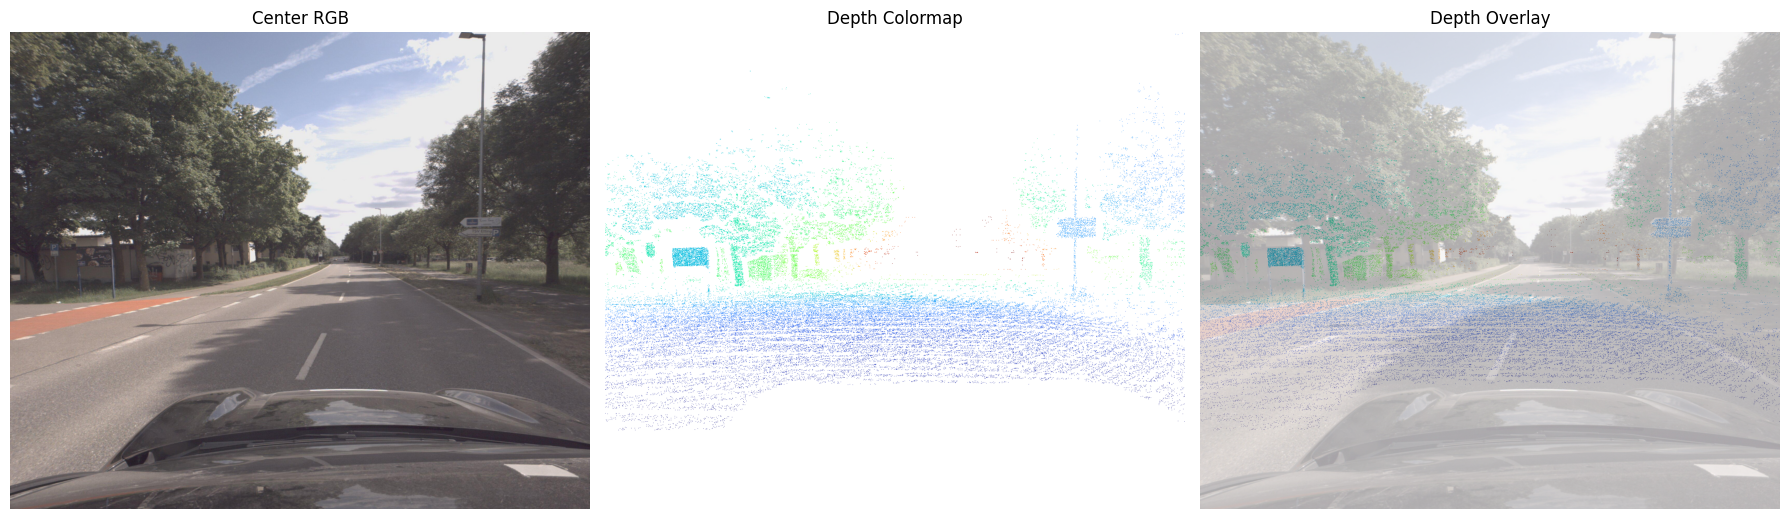

In [62]:
# Inline: Center RGB, Depth colormap, and Depth overlay
# Do not save to disk; display inline

# Center RGB
center_img = rgb0.copy()

# Depth colormap + overlay
imgs = [("Center RGB", center_img)]
if depth_gt is not None:
    d_cm = depth_to_colormap_cv(depth_gt, vmin=0.1, vmax=60.0)
    #make the baackground color as white or invalid
    d_cm = np.where(d_cm == np.array([255, 255, 255], np.uint8), np.array([255, 255, 255], np.uint8), d_cm)
    d_ov = overlay(center_img, d_cm, 0.6)
    imgs += [("Depth Colormap", d_cm), ("Depth Overlay", d_ov)]
else:
    print('No depth available to visualize')

show_grid(imgs, ncols=3, figsize=(18, 10))

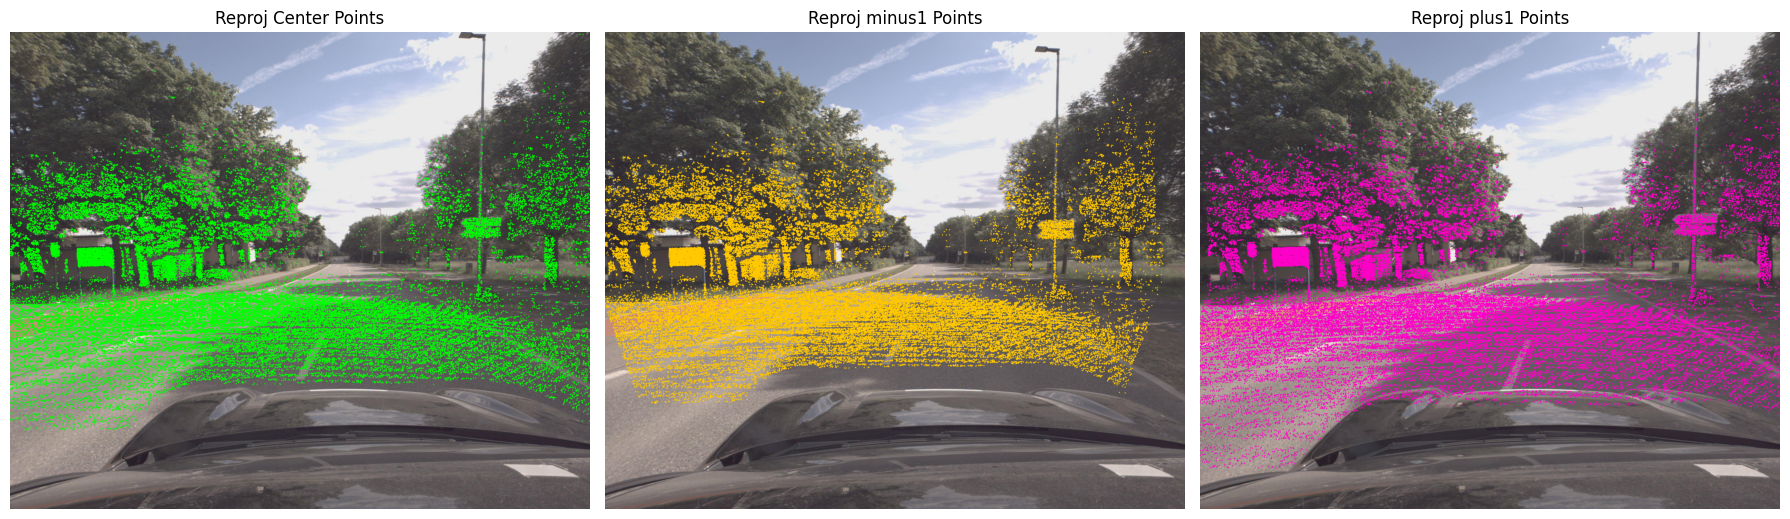

In [63]:
# Inline: Backproject center depth and reproject to center and neighbors
K0 = f0['K'].detach().cpu().numpy()
Tcw0 = f0['T_cam_world'].detach().cpu().numpy()
Twc0 = np.linalg.inv(Tcw0)
pts_c, _ = backproject_depth(depth_gt, K0)
Pw = transform_points(pts_c, Tcw0)  # camera@t -> world

# center reprojection
Pc0 = transform_points(Pw, Twc0)
uv0, m0 = project_points(Pc0, K0, center_img.shape)
img_center_pts = draw_points(center_img, uv0, m0, color=(0, 255, 0), r=1)

grid = [("Reproj Center Points", img_center_pts)]

# neighbors reprojection
for off, tag, color in [(-1, 'minus1', (255, 200, 0)), (1, 'plus1', (255, 0, 200))]:
    fn = frames.get(off)
    if fn is None or fn.get('rgb') is None:
        continue
    rgb_n = chw_to_hwc_uint8(fn['rgb'], ds.rgb_mean[0,0,:], ds.rgb_std[0,0,:])
    Kn = fn['K'].detach().cpu().numpy()
    Tcwn = fn['T_cam_world'].detach().cpu().numpy()
    Twcn = np.linalg.inv(Tcwn)
    Pcn = transform_points(Pw, Twcn)
    uvn, mn = project_points(Pcn, Kn, rgb_n.shape)
    img_n_pts = draw_points(rgb_n, uvn, mn, color=color, r=1)
    title = f"Reproj {tag} Points"
    grid.append((title, img_n_pts))

show_grid(grid, ncols=3, figsize=(18, 10))


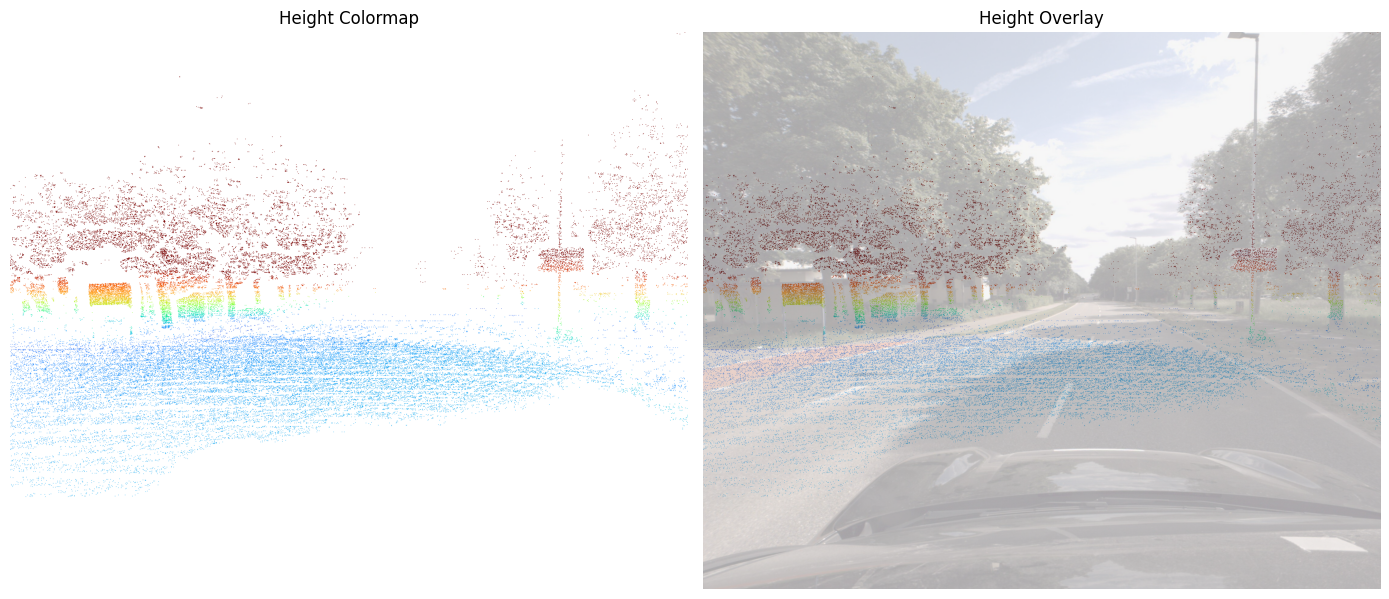

In [64]:
invalid = ~(depth_gt > 0)
h_cm = height_to_colormap(height_gt, vmin=-1.0, vmax=3.0)

h_ov = overlay(center_img, h_cm, 0.6)
show_grid([("Height Colormap", h_cm), ("Height Overlay", h_ov)], ncols=2, figsize=(14, 6))


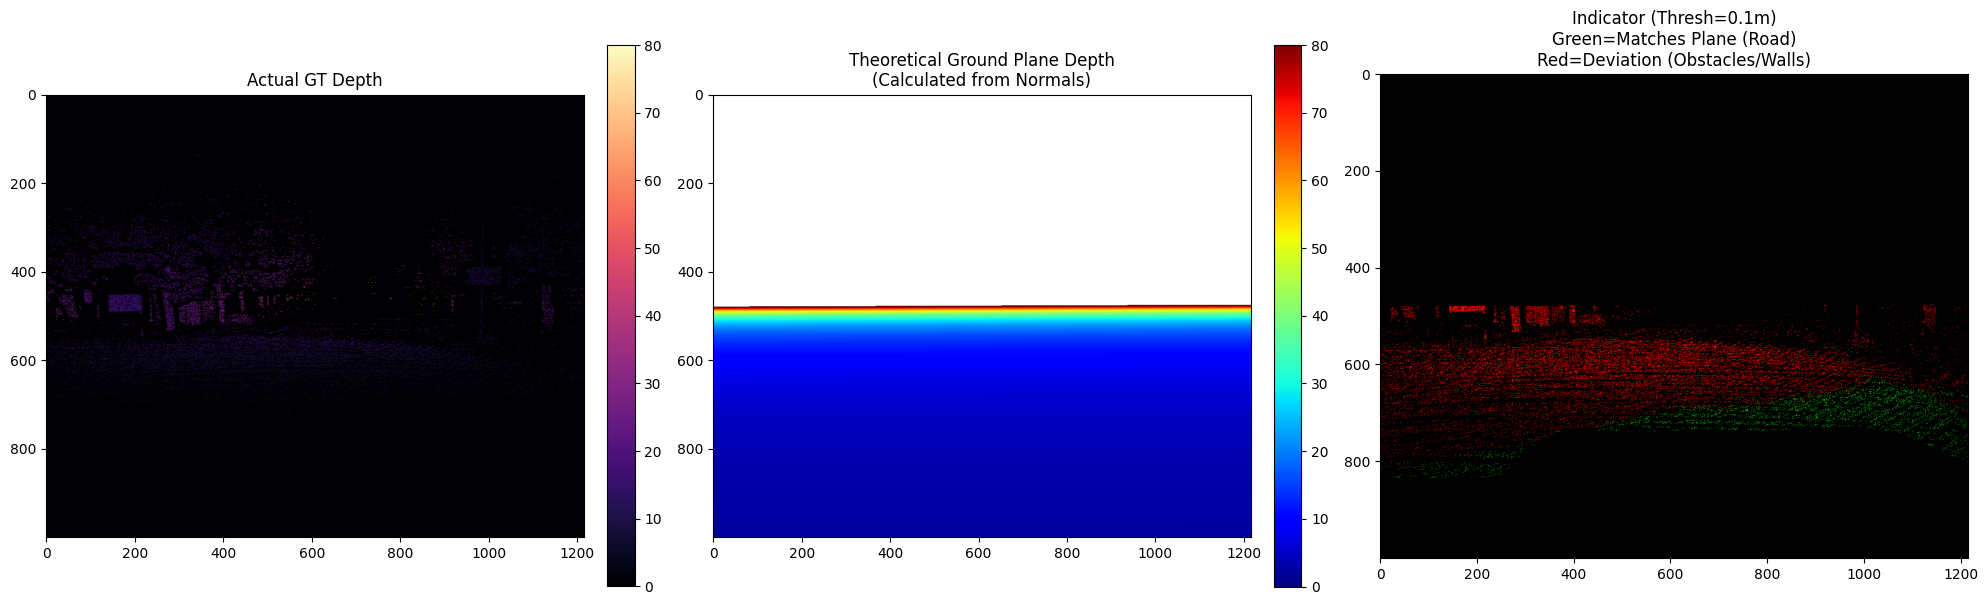

Ground Plane Coverage: 8.08% of valid depth pixels fit the plane.


In [51]:
import torch
import numpy as np
import matplotlib.pyplot as plt

def visualize_ground_plane_check(depth_gt, T_cam_world, gp, K, depth_threshold=0.5):
    """
    Visualizes how well the given ground plane parameters fit the depth GT.
    
    Args:
        depth_gt (torch.Tensor or np.array): Shape (H, W), actual depth.
        T_cam_world (torch.Tensor): Shape (4, 4), Camera-to-World pose.
        gp (dict): Contains 'plane_normal_world' and 'plane_point_world'.
        K (torch.Tensor): Shape (3, 3), Intrinsics.
        depth_threshold (float): Threshold in meters to consider a point "on the ground".
    """
    
    # 1. Standardize inputs to Numpy (CPU)
    def to_numpy(x):
        if isinstance(x, torch.Tensor):
            return x.detach().cpu().numpy()
        return x

    depth_gt = to_numpy(depth_gt)
    T_cw = to_numpy(T_cam_world)
    K_mat = to_numpy(K)
    n_w = to_numpy(gp['plane_normal_world']) # Normal in World
    p_w = to_numpy(gp['plane_point_world'])  # Point in World
    
    H, W = depth_gt.shape

    # 2. Transform Plane to Camera Coordinate System
    # T_cam_world means: P_world = T_cw * P_cam
    # We need rotation from World -> Camera (R_wc) to rotate the normal.
    # R_wc = R_cw.T
    R_cw = T_cw[:3, :3]
    t_cw = T_cw[:3, 3]
    
    # Transform Normal: n_cam = R_wc * n_world
    n_c = R_cw.T @ n_w
    
    # Transform Point: P_cam = R_wc * (P_world - t_cw)
    p_c = R_cw.T @ (p_w - t_cw)
    
    # Plane Equation in Camera: n_c . X = n_c . p_c
    # Let plane_dist = n_c . p_c
    plane_dist_c = np.dot(n_c, p_c)

    # 3. Generate Grid of Rays (Vectorized)
    u, v = np.meshgrid(np.arange(W), np.arange(H))
    # Stack to (3, H*W) -> [u, v, 1]
    pixel_coords = np.stack([u, v, np.ones_like(u)], axis=0).reshape(3, -1)
    
    # Back-project pixels to rays: Ray = K_inv * pixel
    # More numerically stable: Solve K * Ray = pixel
    # But K is small (3x3), inverse is fine.
    K_inv = np.linalg.inv(K_mat)
    rays_c = K_inv @ pixel_coords # Shape (3, H*W)
    
    # 4. Compute Theoretical Ground Depth for every pixel
    # Intersection logic:
    # Point X = Z * Ray
    # n_c . (Z * Ray) = plane_dist_c
    # Z * (n_c . Ray) = plane_dist_c
    # Z = plane_dist_c / (n_c . Ray)
    
    numerator = plane_dist_c
    denominator = n_c @ rays_c # Dot product for every ray
    
    # Avoid division by zero
    denominator[np.abs(denominator) < 1e-6] = 1e-6
    
    depth_plane_flat = numerator / denominator
    depth_plane = depth_plane_flat.reshape(H, W)
    
    # Filter invalid depths (behind camera or too far)
    mask_valid_plane = (depth_plane > 0) & (depth_plane < 100.0) # Cap at 100m for visualization
    depth_plane[~mask_valid_plane] = np.nan

    # 5. Compare with Ground Truth
    # Calculate absolute difference
    diff = np.abs(depth_gt - depth_plane)
    
    # Create a mask where the plane fits the GT (within threshold)
    # We only care where GT is valid (>0) and plane is valid
    valid_comparison_mask = (depth_gt > 0) & mask_valid_plane
    is_ground = (diff < depth_threshold) & valid_comparison_mask

    # 6. Visualization
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    
    # Plot 1: GT Depth
    im1 = axes[0].imshow(depth_gt, cmap='magma', vmin=0, vmax=80)
    axes[0].set_title("Actual GT Depth")
    plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)
    
    # Plot 2: Theoretical Plane Depth
    im2 = axes[1].imshow(depth_plane, cmap='jet', vmin=0, vmax=80)
    axes[1].set_title("Theoretical Ground Plane Depth\n(Calculated from Normals)")
    plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

    # Plot 3: The Indicator / Error Map
    # We will overlay the 'Ground Match' on the image
    # Black = Background/Invalid
    # Red = Object (GT exists but doesn't match Plane)
    # Green = Ground (GT matches Plane)
    
    indicator_img = np.zeros((H, W, 3))
    
    # Objects (Red): Valid GT, but diff is high
    objects_mask = (depth_gt > 0) & valid_comparison_mask & (diff >= depth_threshold)
    indicator_img[objects_mask] = [1, 0, 0] # Red
    
    # Ground (Green): Valid GT, and diff is low
    indicator_img[is_ground] = [0, 1, 0] # Green
    
    axes[2].imshow(indicator_img)
    axes[2].set_title(f"Indicator (Thresh={depth_threshold}m)\nGreen=Matches Plane (Road)\nRed=Deviation (Obstacles/Walls)")
    
    plt.tight_layout()
    plt.show()
    
    # Optional: Print simple score
    ground_pixel_count = np.sum(is_ground)
    total_valid_pixels = np.sum(depth_gt > 0)
    print(f"Ground Plane Coverage: {ground_pixel_count / total_valid_pixels * 100:.2f}% of valid depth pixels fit the plane.")

# --- RUN IT ---
# Assuming variables (depth_gt, f0, gp) are already in your memory from your snippet:
visualize_ground_plane_check(
    depth_gt=depth_gt, 
    T_cam_world=f0['T_cam_world'], 
    gp=gp, 
    K=f0['K'],
    depth_threshold=0.1  # Pixels within 10cm of the theoretical plane are considered "Ground"
)




In [ ]:
# Inline: Synthetic camera rotation test (yaw/pitch/roll)
import math

def euler_ypr_to_R(yaw_deg=0.0, pitch_deg=0.0, roll_deg=0.0):
    y = math.radians(yaw_deg)
    p = math.radians(pitch_deg)
    r = math.radians(roll_deg)
    Ry = np.array([[ math.cos(y), 0, math.sin(y)],
                   [ 0,            1, 0           ],
                   [-math.sin(y), 0, math.cos(y)]], np.float32)
    Rp = np.array([[1, 0,            0           ],
                   [0, math.cos(p), -math.sin(p)],
                   [0, math.sin(p),  math.cos(p)]], np.float32)
    Rr = np.array([[ math.cos(r), -math.sin(r), 0],
                   [ math.sin(r),  math.cos(r), 0],
                   [ 0,            0,            1]], np.float32)
    return Rr @ Rp @ Ry


def rotate_camera_extrinsic(T_cam_world: np.ndarray, yaw=0.0, pitch=0.0, roll=0.0) -> np.ndarray:
    T_new = T_cam_world.copy()
    R_delta = euler_ypr_to_R(yaw, pitch, roll)
    T_new[:3, :3] = R_delta @ T_new[:3, :3]
    return T_new

# Example: rotate +15 deg yaw and redraw ground normal arrow
if gp is not None:
    K0 = f0['K'].detach().cpu().numpy()
    Tcw0 = f0['T_cam_world'].detach().cpu().numpy()
    Tcw_rot = rotate_camera_extrinsic(Tcw0, yaw=15.0, pitch=0.0, roll=0.0)
    Twc_rot = np.linalg.inv(Tcw_rot)

    # plane info
    n_w = gp['plane_normal_world']; p_w = gp['plane_point_world']
    if hasattr(n_w, 'numpy'): n_w = n_w.numpy()
    if hasattr(p_w, 'numpy'): p_w = p_w.numpy()
    n_w = n_w.astype(np.float32); p_w = p_w.astype(np.float32)

    p2_w = p_w + (n_w / (np.linalg.norm(n_w) + 1e-8)) * 3.0

    def world_to_uv_ex(w_pt, Twc):
        pc = transform_points(w_pt.reshape(1, 3), Twc)[0]
        uv, m = project_points(pc.reshape(1, 3), K0, center_img.shape)
        return (uv[0], bool(m[0]))

    uv1, ok1 = world_to_uv_ex(p_w, Twc_rot)
    uv2, ok2 = world_to_uv_ex(p2_w, Twc_rot)
    img_rot = center_img.copy()
    if ok1 and ok2:
        pt1 = tuple(np.round(uv1).astype(int))
        pt2 = tuple(np.round(uv2).astype(int))
        cv2.arrowedLine(img_rot, pt1, pt2, (255, 255, 0), 2, tipLength=0.1)
    show_img("Ground Normal Arrow (Yaw +15°)", img_rot, figsize=(8, 6))
else:
    print('Skip rotation demo: no ground plane info')

In [58]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

class InteractiveCameraSpacePlane:
    def __init__(self, depth_gt, T_cam_world, gp, K, depth_threshold=0.3):
        
        # 1. Convert to Numpy
        self.depth_gt = self.to_numpy(depth_gt)
        self.K = self.to_numpy(K)
        
        # 2. Get Initial Plane in WORLD coordinates
        n_w = self.to_numpy(gp['plane_normal_world'])
        p_w = self.to_numpy(gp['plane_point_world'])
        
        # 3. Transform Plane to CAMERA coordinates
        self.T_cw = self.to_numpy(T_cam_world)
        
        # R_cw: World to Camera Rotation
        self.R_cw = self.T_cw[:3, :3]
        self.t_cw = self.T_cw[:3, 3]
        
        # R_wc: Camera to World Rotation (Inverse of R_cw)
        self.R_wc = self.R_cw.T 
        
        # Transform Normal: n_cam = R_wc * n_world
        self.n_c_init = self.R_wc @ n_w
        
        # Calculate Initial Camera Height (Distance from Cam Center to Plane)
        d_w = np.dot(n_w, p_w)
        self.d_c_init = d_w - np.dot(n_w, self.t_cw)

        self.depth_threshold = depth_threshold
        self.H, self.W = self.depth_gt.shape
        
        # 4. Pre-compute Rays (Static)
        u, v = np.meshgrid(np.arange(self.W), np.arange(self.H))
        pixel_coords = np.stack([u, v, np.ones_like(u)], axis=0).reshape(3, -1)
        K_inv = np.linalg.inv(self.K)
        self.rays_c = K_inv @ pixel_coords 
        
        # Validity Mask
        self.valid_gt_mask = (self.depth_gt > 0) & (self.depth_gt < 80)
        self.total_valid_pixels = np.sum(self.valid_gt_mask)

    def to_numpy(self, x):
        return x.detach().cpu().numpy() if isinstance(x, torch.Tensor) else x

    def get_rotation_matrix(self, pitch, yaw, roll):
        # Conversions to radians
        rx, ry, rz = np.radians([pitch, yaw, roll])
        
        # Pitch (X), Yaw (Y), Roll (Z)
        Rx = np.array([[1, 0, 0], [0, np.cos(rx), -np.sin(rx)], [0, np.sin(rx), np.cos(rx)]])
        Ry = np.array([[np.cos(ry), 0, np.sin(ry)], [0, 1, 0], [-np.sin(ry), 0, np.cos(ry)]])
        Rz = np.array([[np.cos(rz), -np.sin(rz), 0], [np.sin(rz), np.cos(rz), 0], [0, 0, 1]])
        
        return Rz @ Ry @ Rx

    def update_plot(self, dist_offset, pitch, yaw, roll):
        
        # 1. Rotate the Normal Vector (in Camera Space)
        R_user = self.get_rotation_matrix(pitch, yaw, roll)
        n_c_new = R_user @ self.n_c_init
        
        # 2. Adjust Distance (Camera Height)
        cam_height_new = self.d_c_init + dist_offset

        # 3. Compute Depth
        denom = n_c_new @ self.rays_c
        
        with np.errstate(divide='ignore', invalid='ignore'):
            depth_flat = cam_height_new / denom
        
        depth_plane = depth_flat.reshape(self.H, self.W)
        
        # 4. Compare
        mask_valid_plane = (depth_plane > 0)
        diff = np.abs(self.depth_gt - depth_plane)
        matches = (diff < self.depth_threshold) & self.valid_gt_mask & mask_valid_plane
        
        # Score
        score_pct = (np.sum(matches) / self.total_valid_pixels) * 100 if self.total_valid_pixels > 0 else 0

        # --- DATA FOR TITLE ---
        # Convert Camera Normal back to World Normal just for display
        n_w_new = self.R_cw @ n_c_new
        
        # 5. Visualize
        img_vis = np.zeros((self.H, self.W, 3))
        # Red = Mismatch 
        img_vis[self.valid_gt_mask & (~matches)] = [0.8, 0, 0] 
        # Green = Match
        img_vis[matches] = [0, 1, 0]
        
        plt.figure(figsize=(14, 9)) # Slightly taller for extra text
        plt.imshow(img_vis)
        
        # UPDATED TITLE BLOCK
        title_str = (
            f"MATCH: {score_pct:.2f}% (Thresh: {self.depth_threshold}m)\n"
            f"--------------------------------------------------\n"
            f"Camera Height:   {cam_height_new:.3f} m\n"
            f"Normal (World):  [{n_w_new[0]:.4f}, {n_w_new[1]:.4f}, {n_w_new[2]:.4f}]\n"
            f"Normal (Camera): [{n_c_new[0]:.4f}, {n_c_new[1]:.4f}, {n_c_new[2]:.4f}]\n"
            f"Adjustments: Pitch={pitch:.1f} | Yaw={yaw:.1f} | Roll={roll:.1f}"
        )
        
        plt.title(title_str, fontsize=13, loc='left', fontfamily='monospace')
        plt.axis('off')
        plt.show()

# --- RUN UI ---
# Ensure variables (depth_gt, f0, gp) exist
interactor_cam = InteractiveCameraSpacePlane(depth_gt, f0['T_cam_world'], gp, f0['K'], depth_threshold=0.2)

style = {'description_width': '100px'}
layout = widgets.Layout(width='600px')

s_dist = widgets.FloatSlider(min=-2.0, max=2.0, step=0.01, value=0.0, description='Height Adj (m)', style=style, layout=layout)
s_pitch = widgets.FloatSlider(min=-10.0, max=10.0, step=0.05, value=0.0, description='Pitch (X)', style=style, layout=layout)
s_yaw = widgets.FloatSlider(min=-10.0, max=10.0, step=0.05, value=0.0, description='Yaw (Y)', style=style, layout=layout)
s_roll = widgets.FloatSlider(min=-10.0, max=10.0, step=0.05, value=0.0, description='Roll (Z)', style=style, layout=layout)

ui = widgets.VBox([
    widgets.Label(value="<b>Interactive Ground Plane Adjustment</b>"),
    s_dist, s_pitch, s_yaw, s_roll
])

out = widgets.interactive_output(interactor_cam.update_plot, 
                                 {'dist_offset': s_dist, 
                                  'pitch': s_pitch, 
                                  'yaw': s_yaw, 
                                  'roll': s_roll})

display(ui, out)

Output()